# 第 6 章 神奇的马尔科夫链蒙特卡罗方法 —— 代码实现

对应笔记 `docs/mc/ch06.md`。六个实验：有限马尔可夫链收敛到平稳分布、1D Metropolis（步长的影响）、Metropolis–Hastings（忘记校正的后果）、Gibbs（二维正态）、贝叶斯后验采样（Beta-Bernoulli）、Ising 模型相变。

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch06")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2029)

## 6.1 有限马尔可夫链：天气链

晴/雨两态，转移矩阵 P。计算 πPⁿ 收敛到平稳分布 π（解 πP=π）；特征值验证。

平稳分布 π = [0.66666667 0.33333333]（解析 [2/3, 1/3]）
特征值: [1.  0.4]


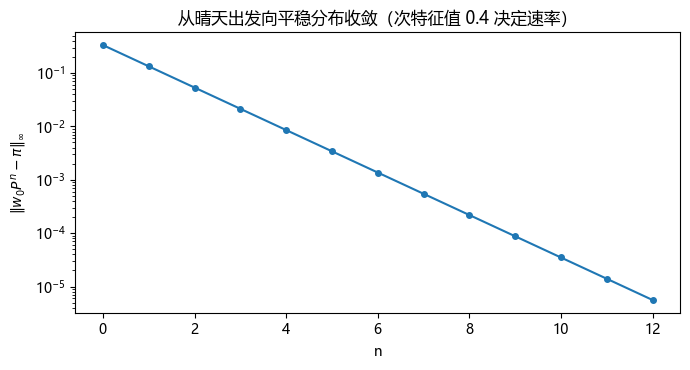

In [9]:
P = np.array([[0.8, 0.2],
              [0.4, 0.6]])           # 行：今天状态；列：明天状态
w, V = np.linalg.eig(P.T)
pi = np.real(V[:, np.isclose(w, 1)][:, 0]); pi = pi / pi.sum()
print(f"平稳分布 π = {pi}（解析 [2/3, 1/3]）")
print("特征值:", np.round(w, 4))

w0 = np.array([1.0, 0.0])            # 从“晴天”出发
errs = [np.abs(w0 @ np.linalg.matrix_power(P, n) - pi).max() for n in range(0, 13)]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(range(13), errs, "o-", ms=4)
ax.set(xlabel="n", ylabel=r"$\|w_0P^n - \pi\|_\infty$", title="从晴天出发向平稳分布收敛（次特征值 0.4 决定速率）")
fig.tight_layout(); save(fig, "out-markov.png"); plt.show()

## 6.3 Metropolis：双势阱与步长的影响

目标 $\pi(x)\propto e^{-(x^2-4)^2/2}$（双峰 ±2）。随机游走提议 $x'=x+\sigma\varepsilon$，对称 → 接受率 $\min(1,\pi(x')/\pi(x))$。σ=0.5（粘峰）vs σ=3（自由跨越）。

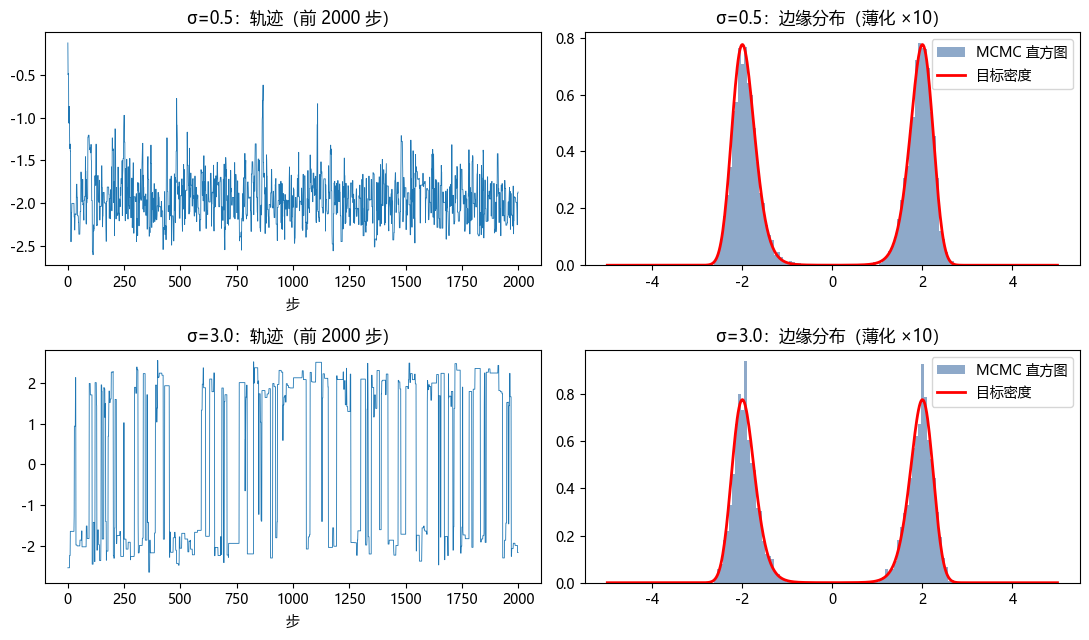

σ=0.5: 右峰占比 0.510（两峰等权 → 0.5），每千步过零 0.2 次
σ=3.0: 右峰占比 0.512（两峰等权 → 0.5），每千步过零 49.1 次


In [10]:
def metropolis_1d(n, sigma, x0=0.0):
    x, chain = x0, np.empty(n)
    for i in range(n):
        xp = x + sigma * rng.standard_normal()
        if np.log(rng.random()) < -((xp**2 - 4)**2 - (x**2 - 4)**2) / 2:
            x = xp
        chain[i] = x
    return chain

n = 40_000
chains = {0.5: metropolis_1d(n, 0.5), 3.0: metropolis_1d(n, 3.0)}
xx = np.linspace(-5, 5, 500)
target = np.exp(-((xx**2 - 4)**2) / 2); target /= np.trapezoid(target, xx)

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for k, (sg, ch) in enumerate(chains.items()):
    axes[k, 0].plot(ch[:2000], lw=0.6)
    axes[k, 0].set(title=f"σ={sg}：轨迹（前 2000 步）", xlabel="步")
    axes[k, 1].hist(ch[::10], bins=80, density=True, color="#8ea9c9", label="MCMC 直方图")
    axes[k, 1].plot(xx, target, "r-", lw=2, label="目标密度")
    axes[k, 1].set(title=f"σ={sg}：边缘分布（薄化 ×10）"); axes[k, 1].legend()
fig.tight_layout(); save(fig, "out-metropolis.png"); plt.show()
for sg, ch in chains.items():
    crossings = np.sum(np.diff(np.sign(ch)) != 0) / len(ch) * 1000
    print(f"σ={sg}: 右峰占比 {np.mean(ch > 0):.3f}（两峰等权 → 0.5），每千步过零 {crossings:.1f} 次")

## 6.4 Metropolis–Hastings：忘记校正的后果

目标：半正态（x>0）。提议：独立地 $x'\sim Exp(1)$（非对称，$q(x'|x)=e^{-x'}$）。正确 MH vs 忘掉 q 比值的“伪 MH”。

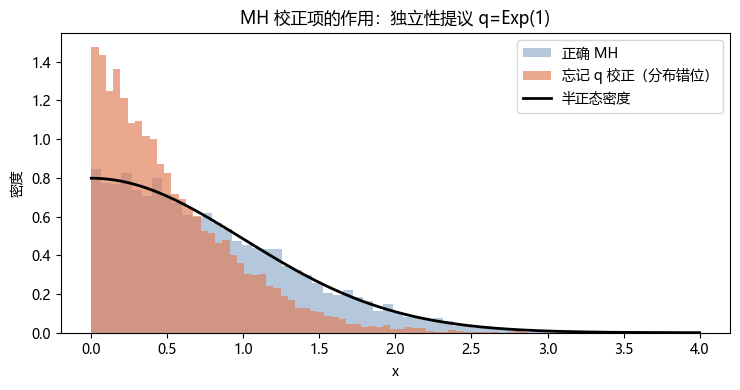

均值：正确 0.797（理论 0.798），错误 0.525


In [11]:
def mh_halfnormal(n, correct=True):
    x, out = 1.0, np.empty(n)
    for i in range(n):
        xp = rng.exponential(1.0)
        # ln α = ln π(x') - ln π(x) + ln q(x|x') - ln q(x'|x)，q(t)=e^{-t}
        log_ratio = (-xp**2/2 + x**2/2) + (xp - x if correct else 0.0)
        if np.log(rng.random()) < min(0.0, log_ratio):
            x = xp
        out[i] = x
    return out

n = 60_000
good, bad = mh_halfnormal(n, True), mh_halfnormal(n, False)
xx = np.linspace(0, 4, 400)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(good[::5], bins=60, density=True, alpha=0.65, color="#8ea9c9", label="正确 MH")
ax.hist(bad[::5], bins=60, density=True, alpha=0.65, color="#e07b54", label="忘记 q 校正（分布错位）")
ax.plot(xx, np.sqrt(2/np.pi)*np.exp(-xx**2/2), "k-", lw=2, label="半正态密度")
ax.set(title="MH 校正项的作用：独立性提议 q=Exp(1)", xlabel="x", ylabel="密度")
ax.legend(); fig.tight_layout(); save(fig, "out-mh.png"); plt.show()
print(f"均值：正确 {good.mean():.3f}（理论 {np.sqrt(2/np.pi):.3f}），错误 {bad.mean():.3f}")

## 6.5 Gibbs：二维正态

ρ=0.8：$X_1|X_2\sim N(ρx_2, 1-ρ^2)$，$X_2|X_1\sim N(ρx_1, 1-ρ^2)$ 轮流抽。与直接抽样对比。

Gibbs 样本相关 0.8018，直接抽样相关 0.7966（理论 0.8）


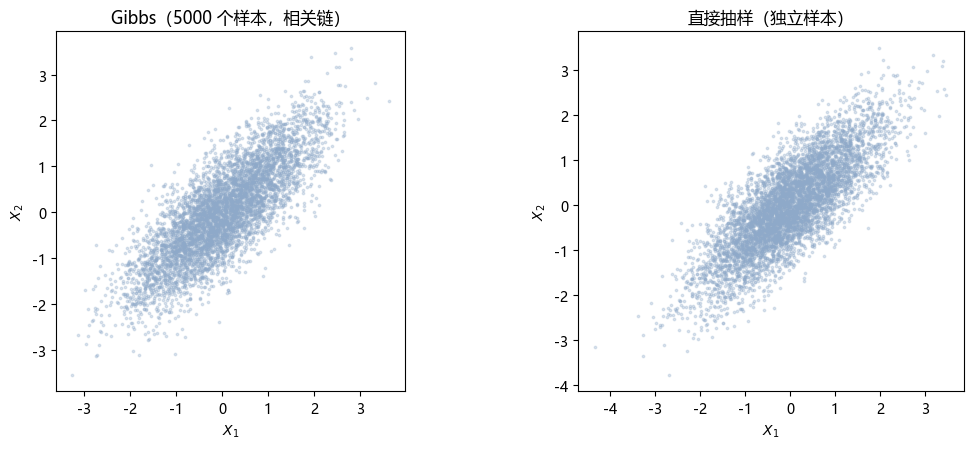

In [12]:
rho, n = 0.8, 6000
x1, x2 = 0.0, 0.0
G = np.empty((n, 2))
for i in range(n):
    x1 = rho * x2 + np.sqrt(1 - rho**2) * rng.standard_normal()
    x2 = rho * x1 + np.sqrt(1 - rho**2) * rng.standard_normal()
    G[i] = (x1, x2)

Z = rng.normal(0, 1, (n, 2))
Z[:, 1] = rho * Z[:, 0] + np.sqrt(1 - rho**2) * Z[:, 1]
print(f"Gibbs 样本相关 {np.corrcoef(G.T)[0,1]:.4f}，直接抽样相关 {np.corrcoef(Z.T)[0,1]:.4f}（理论 0.8）")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, D, name in [(axes[0], G[500:], "Gibbs（5000 个样本，相关链）"), (axes[1], Z, "直接抽样（独立样本）")]:
    ax.scatter(D[:, 0], D[:, 1], s=3, alpha=0.3, color="#8ea9c9")
    ax.set(title=name, aspect="equal", xlabel="$X_1$", ylabel="$X_2$")
fig.tight_layout(); save(fig, "out-gibbs.png"); plt.show()

## 6.6 贝叶斯推断：Beta–Bernoulli 共轭 vs MCMC

先验 Beta(2,2)，掷 20 次得 15 正。解析后验 Beta(17,7)；MCMC 只用未归一化的“似然×先验”。

后验均值：解析 0.7083，MCMC 0.7076


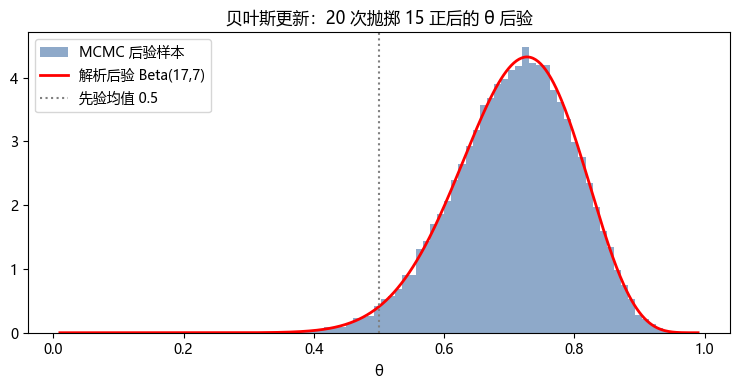

In [13]:
k_heads, n_flips = 15, 20

def metropolis_posterior(n):
    x, out = 0.5, np.empty(n)
    def logp(t):                      # 未归一化后验 ∝ θ^(1+15)(1-θ)^(1+5) = Beta(17,7)
        return (1 + k_heads) * np.log(t) + (1 + n_flips - k_heads) * np.log(1 - t)
    for i in range(n):
        xp = x + 0.1 * rng.standard_normal()
        if 0 < xp < 1 and np.log(rng.random()) < logp(xp) - logp(x):
            x = xp
        out[i] = x
    return out

post = metropolis_posterior(60_000)[1000:]
a_post, b_post = 2 + k_heads, 2 + n_flips - k_heads
xx = np.linspace(0.01, 0.99, 500)
print(f"后验均值：解析 {a_post/(a_post+b_post):.4f}，MCMC {post.mean():.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(post, bins=60, density=True, color="#8ea9c9", label="MCMC 后验样本")
ax.plot(xx, stats.beta.pdf(xx, a_post, b_post), "r-", lw=2, label=f"解析后验 Beta({a_post},{b_post})")
ax.axvline(0.5, color="gray", ls=":", lw=1.5, label="先验均值 0.5")
ax.set(title="贝叶斯更新：20 次抛掷 15 正后的 θ 后验", xlabel="θ"); ax.legend()
fig.tight_layout(); save(fig, "out-bayes.png"); plt.show()

## 6.7 Ising 模型：Metropolis 的高级应用

2D Ising（周期边界，能量 $E=-\sum s_is_j$）。单点翻转 Metropolis：$\Delta E\le 0$ 接受，否则概率 $e^{-\Delta E/T}$。左：T=2.2（临界下）与 T=3.5 的构型；右：磁化强度 |m| 随 T（临界温度 ≈2.27）。

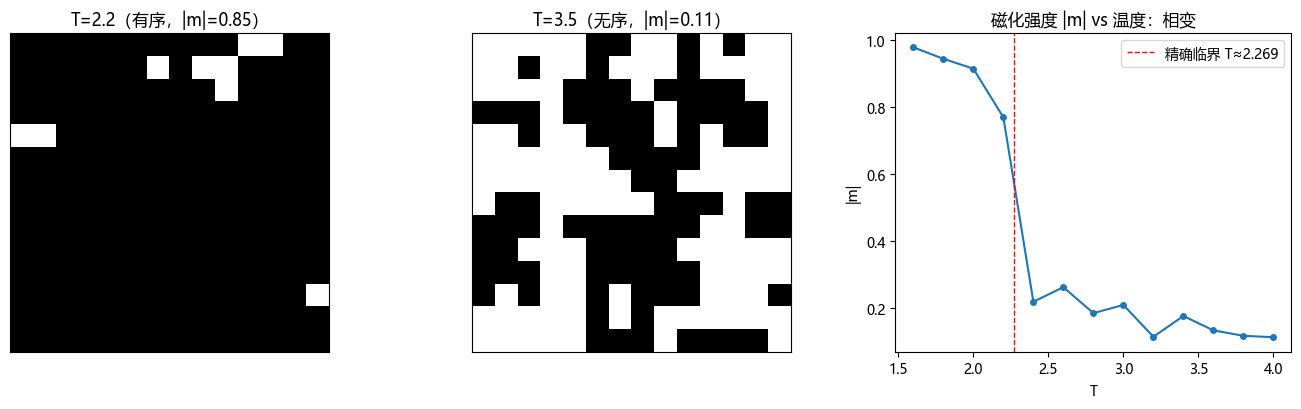

In [14]:
def ising_metro(L, T, burn, meas, rng):
    s = rng.choice([-1, 1], (L, L))
    m_vals = []
    for sweep in range(burn + meas):
        for _ in range(L * L):
            a, b = int(rng.integers(L)), int(rng.integers(L))
            dE = 2 * s[a, b] * (s[(a+1)%L, b] + s[(a-1)%L, b] + s[a, (b+1)%L] + s[a, (b-1)%L])
            if dE <= 0 or rng.random() < np.exp(-dE / T):
                s[a, b] = -s[a, b]
        if sweep >= burn:
            m_vals.append(abs(s.mean()))
    return s, np.mean(m_vals)

L, burn, meas = 14, 150, 60
s_lo, m_lo = ising_metro(L, 2.2, burn, meas, rng)
s_hi, m_hi = ising_metro(L, 3.5, burn, meas, rng)
Temps = np.arange(1.6, 4.01, 0.2)
mags = [ising_metro(L, T, burn, meas, rng)[1] for T in Temps]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
axes[0].imshow(s_lo, cmap="gray"); axes[0].set(title=f"T=2.2（有序，|m|={m_lo:.2f}）", xticks=[], yticks=[])
axes[1].imshow(s_hi, cmap="gray"); axes[1].set(title=f"T=3.5（无序，|m|={m_hi:.2f}）", xticks=[], yticks=[])
axes[2].plot(Temps, mags, "o-", ms=4)
axes[2].axvline(2.269, color="r", ls="--", lw=1, label="精确临界 T≈2.269")
axes[2].set(title="磁化强度 |m| vs 温度：相变", xlabel="T", ylabel="|m|"); axes[2].legend()
fig.tight_layout(); save(fig, "out-ising.png"); plt.show()